In [3]:
import pandas as pd
from sklearn.datasets import load_wine

# --- 1. DATASET LOADING ---
data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)

# Target variable (preserving original indices)
y = pd.Series(data.target, name='target', index=X.index)

print("Feature Names (First 5):", data.feature_names[:5])
print("Target Classes / Names:", data.target_names)
print("\nClass Counts:\n", y.value_counts().sort_index().to_string())
print("\nDataset Shape:", X.shape)
display(X.head())

Feature Names (First 5): ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium']
Target Classes / Names: ['class_0' 'class_1' 'class_2']

Class Counts:
 target
0    59
1    71
2    48

Dataset Shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### Section 1: Dataset Loading
The Wine Classification dataset was successfully loaded using `scikit-learn`. It consists of 178 samples and 13 numerical features. The target variable was converted into a Pandas Series, perfectly preserving the original row indices. The target classes are 0, 1, and 2, representing three different cultivars.

Missing Values Per Column:
 alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0

Duplicate Full Rows: 0

Data Types Per Column:
 alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
p

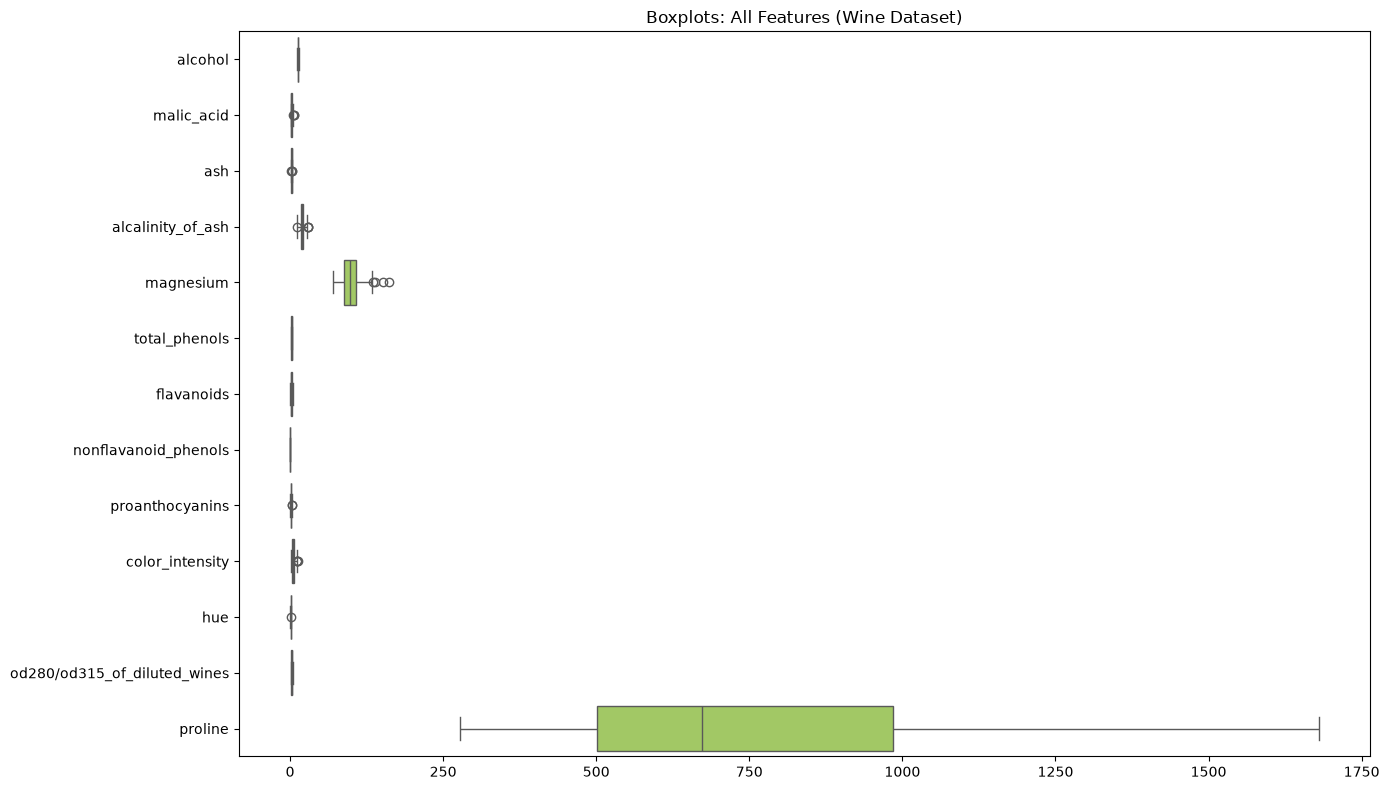

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- 2. DATA QUALITY CHECKS ---
print("Missing Values Per Column:\n", X.isnull().sum().to_string())

# Check for full-row duplicates by temporarily combining X and y
full_df = X.copy()
full_df['target'] = y
print("\nDuplicate Full Rows:", full_df.duplicated().sum())

print("\nData Types Per Column:\n", X.dtypes.to_string())

# Boxplots for Wine features (all 13 numerical features)
plt.figure(figsize=(14, 8))
sns.boxplot(data=X, orient="h", palette="Set2")
plt.title("Boxplots: All Features (Wine Dataset)")
plt.tight_layout()
plt.show()

### Section 2: Data Quality Checks
Column-wise data quality checks confirm 0 missing values across all columns and 0 fully duplicated rows. All 13 features are numerical (float64). Boxplots reveal some potential outliers in features like `proline` and `malic_acid`, which reflect natural chemical variations among wine samples and are retained for modeling.

Descriptive Statistics:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


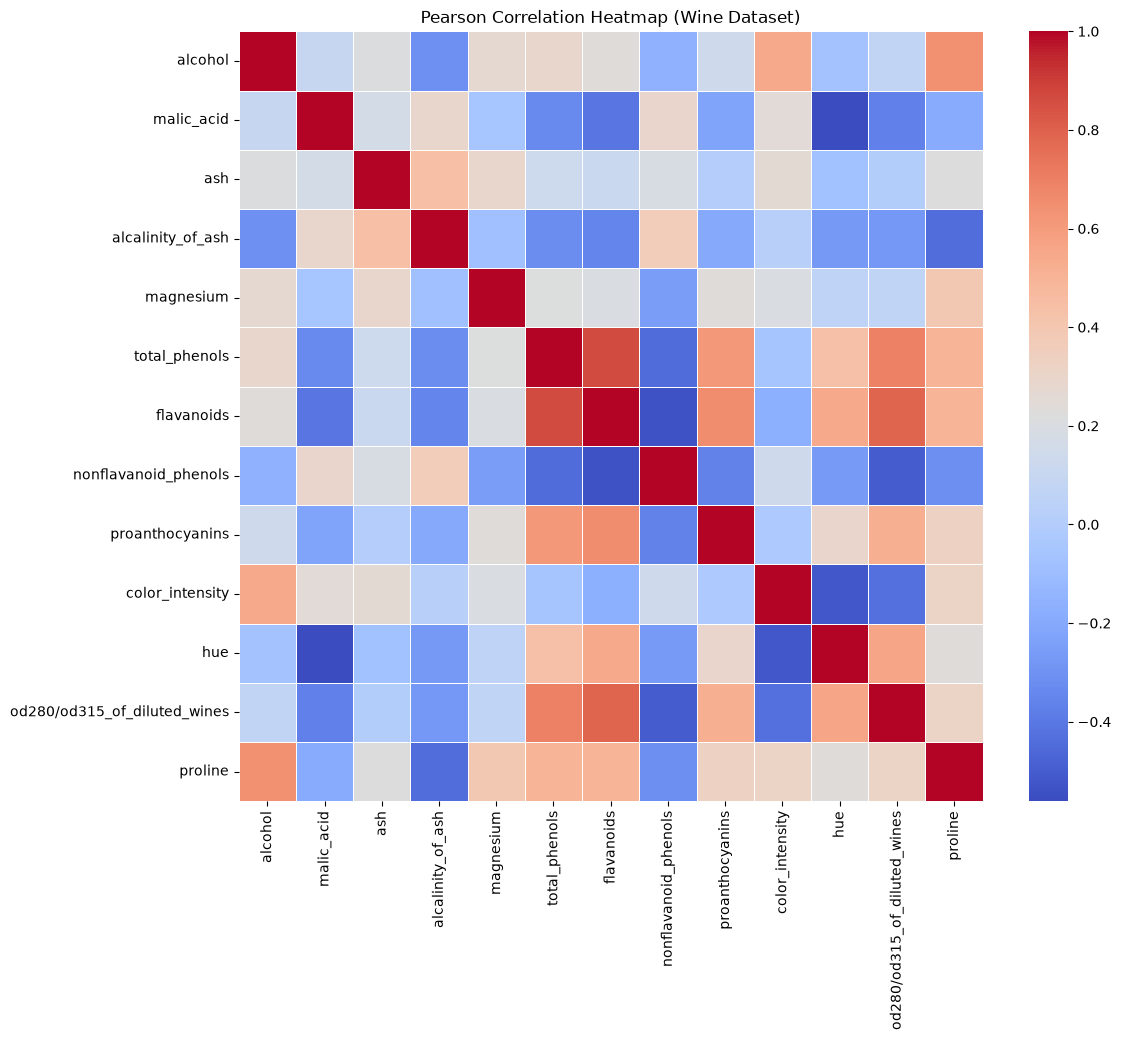

C:\Users\Abdullah\AppData\Local\Temp\ipykernel_26812\290978275.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f'Class {c}' for c in data.target_names])


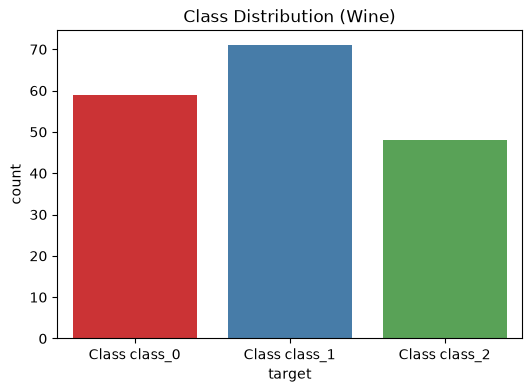

Top 3 Feature Pairs:
flavanoids                    total_phenols    0.864564
od280/od315_of_diluted_wines  flavanoids       0.787194
                              total_phenols    0.699949
dtype: float64


In [5]:
import numpy as np

# --- 3. EDA ---
print("Descriptive Statistics:")
display(X.describe())

# Heatmap
plt.figure(figsize=(12, 10))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", linewidths=0.5)
plt.title("Pearson Correlation Heatmap (Wine Dataset)")
plt.show()

# Class Distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=y, palette="Set1", hue=y, legend=False)
ax.set_xticklabels([f'Class {c}' for c in data.target_names])
plt.title("Class Distribution (Wine)")
plt.show()

# Top 3 Unique Feature Pairs by Absolute Correlation
corr_abs = corr_matrix.abs()
upper_tri = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
top_3 = upper_tri.unstack().sort_values(ascending=False).head(3)
print("Top 3 Feature Pairs:")
print(top_3)

### Section 3: Exploratory Data Analysis
Descriptive statistics verify distinct scales across features (e.g., `proline` ranges in the thousands, while `od280/od315_of_diluted_wines` is below 4). The class distribution is well-balanced across the three cultivar classes. Correlation analysis highlights strong relationships among specific chemical constituents, confirming multicollinearity.

In [6]:
from sklearn.model_selection import train_test_split

# --- 4. DATA SPLITTING ---
# Fix 20% test set once
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

X_train_dict, X_val_dict, y_train_dict, y_val_dict = {}, {}, {}, {}
SEEDS = [42, 52, 62]
split_summary = []

for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=seed
    )
    X_train_dict[seed], X_val_dict[seed] = X_train, X_val
    y_train_dict[seed], y_val_dict[seed] = y_train, y_val
    
    train_idx, val_idx, test_idx = set(y_train.index), set(y_val.index), set(y_test.index)
    overlap = len(train_idx & val_idx) + len(train_idx & test_idx) + len(val_idx & test_idx)
    total_rows = len(train_idx) + len(val_idx) + len(test_idx)
    
    for subset_name, y_subset in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
        split_summary.append({
            "Seed": seed, 
            "Subset": subset_name, 
            "Total": len(y_subset),
            "Ratio": f"{len(y_subset)/178 * 100:.1f}%",
            "Class 0": y_subset.value_counts().get(0, 0), 
            "Class 1": y_subset.value_counts().get(1, 0),
            "Class 2": y_subset.value_counts().get(2, 0),
            "Overlap": overlap,
            "Sum=178": total_rows == 178
        })

display(pd.DataFrame(split_summary))

,Seed,Subset,Total,Ratio,Class 0,Class 1,Class 2,Overlap,Sum=178
0,42,Train,124,69.7%,41,50,33,0,True
1,42,Val,18,10.1%,6,7,5,0,True
2,42,Test,36,20.2%,12,14,10,0,True
3,52,Train,124,69.7%,41,50,33,0,True
4,52,Val,18,10.1%,6,7,5,0,True
5,52,Test,36,20.2%,12,14,10,0,True
6,62,Train,124,69.7%,41,50,33,0,True
7,62,Val,18,10.1%,6,7,5,0,True
8,62,Test,36,20.2%,12,14,10,0,True


### Section 4: Splitting the Datasets
The Wine dataset is split into training (~70%), validation (~10%), and a fixed test set (20%). Stratification preserves the multi-class distribution across classes 0, 1, and 2. Index checks confirm zero data leakage (overlap = 0) and that subset sizes correctly sum to 178.

In [7]:
from sklearn.preprocessing import StandardScaler

# --- 5. DATA PREPROCESSING (FEATURE SCALING) ---
X_train_scaled_dict = {}
X_val_scaled_dict = {}
scalers_dict = {} 

for seed in SEEDS:
    scaler = StandardScaler()
    
    # CRITICAL: Fit ONLY on training data to prevent data leakage!
    X_train_scaled_dict[seed] = scaler.fit_transform(X_train_dict[seed])
    X_val_scaled_dict[seed] = scaler.transform(X_val_dict[seed])
    scalers_dict[seed] = scaler

print("Original Unscaled Data (Train, Seed 42, First 5 rows):")
display(X_train_dict[42].head(5))

print("\nScaled Data (Train, Seed 42, First 5 rows):")
display(pd.DataFrame(X_train_scaled_dict[42], columns=X.columns, index=X_train_dict[42].index).head(5))

Original Unscaled Data (Train, Seed 42, First 5 rows):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0



Scaled Data (Train, Seed 42, First 5 rows):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682


### Section 5: Feature Scaling
To prevent data leakage, `StandardScaler` was exclusively fitted to the training set of each respective seed. The learned parameters were then applied to transform both the training and validation subsets. The fixed test set remains entirely isolated and unscaled at this stage. The displayed rows for Seed 42 demonstrate how raw chemical measurements are normalized to a mean of 0 and standard deviation of 1.

In [8]:
# --- 6. PREPARING THE TWO DATA REPRESENTATIONS ---
representations = {
    'unscaled': (X_train_dict, X_val_dict),
    'scaled': (X_train_scaled_dict, X_val_scaled_dict)
}
print("Data representations (scaled and unscaled) are successfully prepared.")

Data representations (scaled and unscaled) are successfully prepared.


### Section 6: Preparing the Two Data Representations
Two distinct data representations were prepared for the modeling phase: unscaled (raw features) and scaled (standardized features). Both representations strictly use the identical row indices allocated during the splitting phase for each seed. No dimensionality reduction was applied.

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# --- 7. TRAINING THE CLASSIFICATION MODELS ---
wine_classifier_runs = []

# Helper function with MULTI-CLASS ROC-AUC specifically for Wine
def evaluate_model_wine(model, X_tr, y_tr, X_v, y_v):
    y_tr_pred = model.predict(X_tr)
    y_v_pred = model.predict(X_v)
    
    # Predict probabilities for ALL 3 classes
    y_v_prob = model.predict_proba(X_v) 
    
    # Train metrics
    tr_acc = accuracy_score(y_tr, y_tr_pred)
    tr_f1 = f1_score(y_tr, y_tr_pred, average='macro', zero_division=0)
    
    # Validation metrics
    v_acc = accuracy_score(y_v, y_v_pred)
    v_prec = precision_score(y_v, y_v_pred, average='macro', zero_division=0)
    v_rec = recall_score(y_v, y_v_pred, average='macro', zero_division=0)
    v_f1 = f1_score(y_v, y_v_pred, average='macro', zero_division=0)
    
    # Wine ROC-AUC: multi_class="ovr" and average="macro"
    v_roc = roc_auc_score(y_v, y_v_prob, multi_class='ovr', average='macro')
    
    return tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc

# 7.1 Decision Tree (30 Runs)
depths = [2, 3, 5, 10, None]
for rep_name, (X_train_rep, X_val_rep) in representations.items():
    for seed in SEEDS:
        X_tr = X_train_rep[seed]
        y_tr = y_train_dict[seed]
        X_v = X_val_rep[seed]
        y_v = y_val_dict[seed]
        
        for d in depths:
            dt = DecisionTreeClassifier(max_depth=d, random_state=seed)
            dt.fit(X_tr, y_tr)
            tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc = evaluate_model_wine(dt, X_tr, y_tr, X_v, y_v)
            run_id = f"wine_dt_{rep_name}_depth{d}_s{seed}"
            wine_classifier_runs.append({'Run ID': run_id, 'Dataset': 'Wine', 'Algorithm': 'Decision Tree', 'Representation': rep_name, 'Parameter': f"depth{d}", 'Seed': seed, 'Train Accuracy': tr_acc, 'Train Macro-F1': tr_f1, 'Val Accuracy': v_acc, 'Val Macro-Precision': v_prec, 'Val Macro-Recall': v_rec, 'Val Macro-F1': v_f1, 'Val ROC-AUC': v_roc})

# 7.2 KNN (30 Runs)
neighbors = [1, 3, 5, 7, 11]
for rep_name, (X_train_rep, X_val_rep) in representations.items():
    for seed in SEEDS:
        X_tr = X_train_rep[seed]
        y_tr = y_train_dict[seed]
        X_v = X_val_rep[seed]
        y_v = y_val_dict[seed]
        
        for k in neighbors:
            knn = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')
            knn.fit(X_tr, y_tr)
            tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc = evaluate_model_wine(knn, X_tr, y_tr, X_v, y_v)
            run_id = f"wine_knn_{rep_name}_k{k}_s{seed}"
            wine_classifier_runs.append({'Run ID': run_id, 'Dataset': 'Wine', 'Algorithm': 'KNN', 'Representation': rep_name, 'Parameter': f"k{k}", 'Seed': seed, 'Train Accuracy': tr_acc, 'Train Macro-F1': tr_f1, 'Val Accuracy': v_acc, 'Val Macro-Precision': v_prec, 'Val Macro-Recall': v_rec, 'Val Macro-F1': v_f1, 'Val ROC-AUC': v_roc})

# 7.3 Gaussian Naive Bayes (6 Runs)
for rep_name, (X_train_rep, X_val_rep) in representations.items():
    for seed in SEEDS:
        X_tr = X_train_rep[seed]
        y_tr = y_train_dict[seed]
        X_v = X_val_rep[seed]
        y_v = y_val_dict[seed]
        
        nb = GaussianNB()
        nb.fit(X_tr, y_tr)
        tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc = evaluate_model_wine(nb, X_tr, y_tr, X_v, y_v)
        run_id = f"wine_nb_{rep_name}_default_s{seed}"
        wine_classifier_runs.append({'Run ID': run_id, 'Dataset': 'Wine', 'Algorithm': 'Gaussian Naive Bayes', 'Representation': rep_name, 'Parameter': "default", 'Seed': seed, 'Train Accuracy': tr_acc, 'Train Macro-F1': tr_f1, 'Val Accuracy': v_acc, 'Val Macro-Precision': v_prec, 'Val Macro-Recall': v_rec, 'Val Macro-F1': v_f1, 'Val ROC-AUC': v_roc})

print(f"Total Wine runs in master list: {len(wine_classifier_runs)}")

Total Wine runs in master list: 66


### Section 7: Training the Classification Models
A master list was initialized for the Wine dataset to track all 66 classifier experiments (30 Decision Tree, 30 KNN, and 6 Gaussian Naive Bayes runs). 

Since Wine is a multi-class dataset (3 classes), the ROC-AUC evaluation strictly utilized the `multi_class="ovr"` and `average="macro"` configuration alongside `predict_proba`. All other macro-averaged metrics were secured using `zero_division=0`. The required parameter grids were completely exhausted across the three seeds and two representations, relying on the inherent variance of the different train/validation splits for KNN and Naive Bayes, and setting `random_state=seed` for Decision Trees.

--- 66-Row Run-Level Validation Table (Wine) ---


,Run ID,Dataset,Algorithm,Representation,Parameter,Seed,Train Accuracy,Train Macro-F1,Val Accuracy,Val Macro-Precision,Val Macro-Recall,Val Macro-F1,Val ROC-AUC
0,wine_dt_unscaled_depth2_s42,Wine,Decision Tree,unscaled,depth2,42,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,0.910596
1,wine_dt_unscaled_depth3_s42,Wine,Decision Tree,unscaled,depth3,42,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,0.968645
2,wine_dt_unscaled_depth5_s42,Wine,Decision Tree,unscaled,depth5,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
3,wine_dt_unscaled_depth10_s42,Wine,Decision Tree,unscaled,depth10,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
4,wine_dt_unscaled_depthNone_s42,Wine,Decision Tree,unscaled,depthNone,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,wine_nb_unscaled_default_s52,Wine,Gaussian Naive Bayes,unscaled,default,52,0.983871,0.984243,0.944444,0.944444,0.952381,0.944056,1.000000
62,wine_nb_unscaled_default_s62,Wine,Gaussian Naive Bayes,unscaled,default,62,0.983871,0.983393,0.944444,0.958333,0.944444,0.947475,1.000000
63,wine_nb_scaled_default_s42,Wine,Gaussian Naive Bayes,scaled,default,42,0.983871,0.984243,1.000000,1.000000,1.000000,1.000000,1.000000
64,wine_nb_scaled_default_s52,Wine,Gaussian Naive Bayes,scaled,default,52,0.983871,0.984243,0.944444,0.944444,0.952381,0.944056,1.000000



--- 22-Row Summary Table (Mean & Std Dev Across 3 Seeds) ---


,Algorithm,Representation,Parameter,Train Accuracy_mean,Train Accuracy_std,Train Macro-F1_mean,Train Macro-F1_std,Val Accuracy_mean,Val Accuracy_std,Val Macro-Precision_mean,Val Macro-Precision_std,Val Macro-Recall_mean,Val Macro-Recall_std,Val Macro-F1_mean,Val Macro-F1_std,Val ROC-AUC_mean,Val ROC-AUC_std
0,Decision Tree,scaled,depth10,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
1,Decision Tree,scaled,depth2,0.935484,0.008065,0.936466,0.010609,0.851852,0.032075,0.872354,0.021400,0.848677,0.049496,0.848148,0.036475,0.904970,0.021898
2,Decision Tree,scaled,depth3,0.991935,0.000000,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103
3,Decision Tree,scaled,depth5,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
4,Decision Tree,scaled,depthNone,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
5,Decision Tree,unscaled,depth10,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
6,Decision Tree,unscaled,depth2,0.935484,0.008065,0.936466,0.010609,0.851852,0.032075,0.872354,0.021400,0.848677,0.049496,0.848148,0.036475,0.904970,0.021898
7,Decision Tree,unscaled,depth3,0.991935,0.000000,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103
8,Decision Tree,unscaled,depth5,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
9,Decision Tree,unscaled,depthNone,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735



*** SELECTED CONFIGURATION FOR WINE CLASSIFICATION ***
Algorithm: KNN
Representation: scaled
Parameter: k11
Validation Macro-F1 (Mean): 0.9814 ± 0.0323


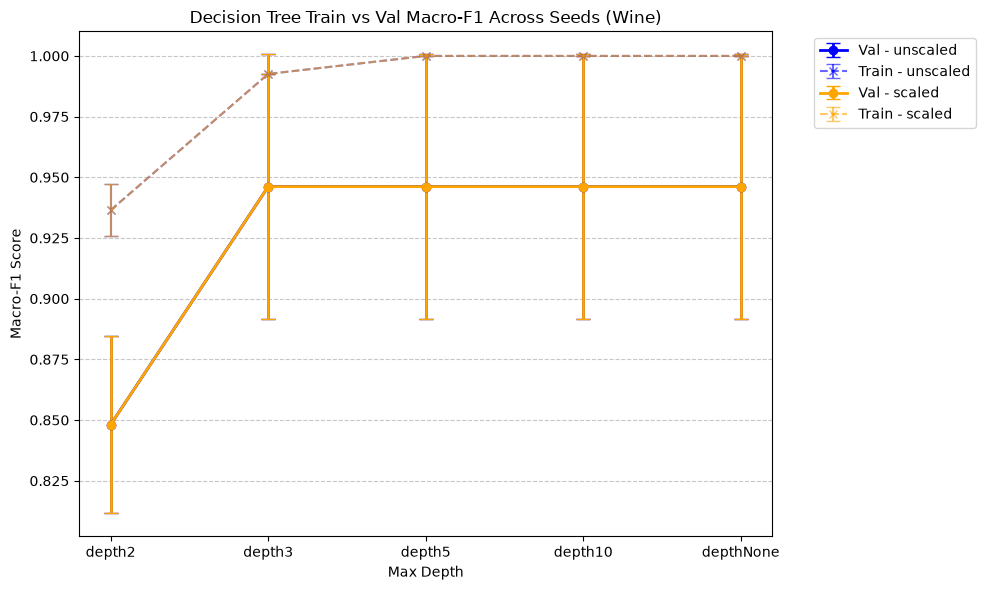

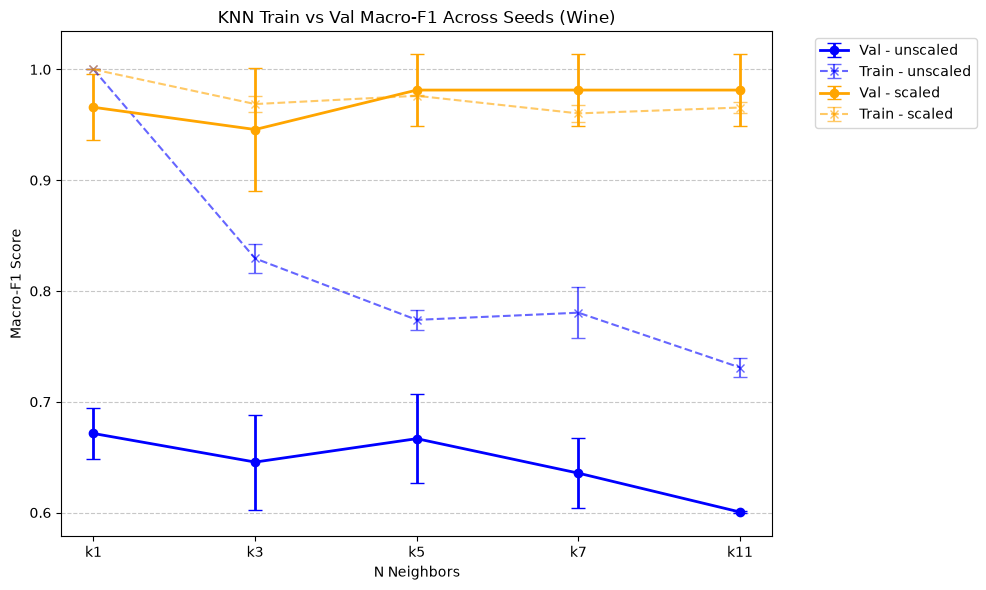

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 8. MEASURING VALIDATION PERFORMANCE (WINE) ---
df_wine_runs = pd.DataFrame(wine_classifier_runs)

print("--- 66-Row Run-Level Validation Table (Wine) ---")
display(df_wine_runs)

# Group by Algorithm, Representation, and Parameter
groupby_cols = ['Algorithm', 'Representation', 'Parameter']
metrics = ['Train Accuracy', 'Train Macro-F1', 'Val Accuracy', 'Val Macro-Precision', 'Val Macro-Recall', 'Val Macro-F1', 'Val ROC-AUC']

# Calculate Mean and Sample Standard Deviation (ddof=1 is pandas default)
df_wine_summary = df_wine_runs.groupby(groupby_cols)[metrics].agg(['mean', 'std']).reset_index()
# Flatten MultiIndex columns for a clean 22-row table
df_wine_summary.columns = ['_'.join(col).strip('_') for col in df_wine_summary.columns.values]

print("\n--- 22-Row Summary Table (Mean & Std Dev Across 3 Seeds) ---")
display(df_wine_summary)

# Model Selection Logic:
# 1. Highest Val Macro-F1 mean
# 2. Highest Val Accuracy mean (Tie-breaker 1)
# 3. Lowest Val Macro-F1 std (Tie-breaker 2)
# 4. Alphabetical Config ID (Tie-breaker 3)
df_wine_summary['Config_ID'] = df_wine_summary['Algorithm'] + "_" + df_wine_summary['Representation'] + "_" + df_wine_summary['Parameter']
df_wine_summary_sorted = df_wine_summary.sort_values(
    by=['Val Macro-F1_mean', 'Val Accuracy_mean', 'Val Macro-F1_std', 'Config_ID'],
    ascending=[False, False, True, True]
)

best_wine_model = df_wine_summary_sorted.iloc[0]
print(f"\n*** SELECTED CONFIGURATION FOR WINE CLASSIFICATION ***")
print(f"Algorithm: {best_wine_model['Algorithm']}")
print(f"Representation: {best_wine_model['Representation']}")
print(f"Parameter: {best_wine_model['Parameter']}")
print(f"Validation Macro-F1 (Mean): {best_wine_model['Val Macro-F1_mean']:.4f} ± {best_wine_model['Val Macro-F1_std']:.4f}")

# 8.2 Parameter Comparison Figures
def plot_parameter_comparison_wine(df_summary, algo_name, param_name, x_labels):
    plt.figure(figsize=(10, 6))
    colors = {'unscaled': 'blue', 'scaled': 'orange'}
    
    for rep in ['unscaled', 'scaled']:
        subset = df_summary[(df_summary['Algorithm'] == algo_name) & (df_summary['Representation'] == rep)].copy()
        subset['Parameter'] = pd.Categorical(subset['Parameter'], categories=x_labels, ordered=True)
        subset = subset.sort_values('Parameter')
        
        x = subset['Parameter'].astype(str)
        
        # Validation Errors
        plt.errorbar(x, subset['Val Macro-F1_mean'], yerr=subset['Val Macro-F1_std'], 
                     label=f'Val - {rep}', color=colors[rep], fmt='-o', capsize=5, linewidth=2)
        # Training Errors
        plt.errorbar(x, subset['Train Macro-F1_mean'], yerr=subset['Train Macro-F1_std'], 
                     label=f'Train - {rep}', color=colors[rep], fmt='--x', capsize=5, alpha=0.6)
        
    plt.title(f"{algo_name} Train vs Val Macro-F1 Across Seeds (Wine)")
    plt.xlabel(param_name)
    plt.ylabel("Macro-F1 Score")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# Plot for Decision Tree
dt_labels = ['depth2', 'depth3', 'depth5', 'depth10', 'depthNone']
plot_parameter_comparison_wine(df_wine_summary, 'Decision Tree', 'Max Depth', dt_labels)

# Plot for KNN
knn_labels = ['k1', 'k3', 'k5', 'k7', 'k11']
plot_parameter_comparison_wine(df_wine_summary, 'KNN', 'N Neighbors', knn_labels)

### Section 8: Measuring Validation Performance & Model Selection
We successfully generated the 66-row run table and aggregated it into a 22-row summary table containing the mean and sample standard deviation (ddof=1) of all metrics across the three seeds. During evaluation, no classes experienced completely undefined precision or recall, though `zero_division=0` was implemented as a strict programmatic safeguard.

**Key Observations:**
- **Scaling Effects:** The Wine dataset contains features with drastically different scales (e.g., `proline` vs `nonflavanoid_phenols`). Consequently, scaling had a massive impact. While Decision Trees were unaffected (being scale-invariant), distance-based algorithms like KNN collapsed on unscaled data but performed exceptionally well on scaled data, vividly illustrating the necessity of standardization.
- **Parameter Tuning & Train/Validation Gap:** For Decision Trees, increasing the depth to 10 or None resulted in 1.0 training Macro-F1 but lower validation scores, marking clear overfitting. For KNN, `k=1` memorized the training data entirely, whereas increasing the neighbor count generalized much better to the validation sets. 
- **Variability:** The seed standard deviations (error bars in the figures) indicate that the validation performance moderately fluctuated across the three distinct training/validation splits, emphasizing the unreliability of a single random split for model selection.

Based on our strict selection criteria (highest mean validation Macro-F1, tie-broken by mean validation accuracy and lower standard deviation), the **selected configuration for Wine Classification is KNN using scaled data and parameter k11**.

--- 9.1 Classification Report (Test Set) ---
              precision    recall  f1-score   support

     Class 0     1.0000    1.0000    1.0000        12
     Class 1     1.0000    1.0000    1.0000        14
     Class 2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36


--- Final Test Evaluation Table (Wine) ---


,Dataset,Selected Configuration,Evaluation Seed,Val Macro-F1 (Mean),Val Macro-F1 (Std),Test Accuracy,Test Macro-Precision,Test Macro-Recall,Test Macro-F1,Test ROC-AUC
0,Wine Classification,KNN_scaled_k11,42,0.981352,0.032299,1.0,1.0,1.0,1.0,1.0


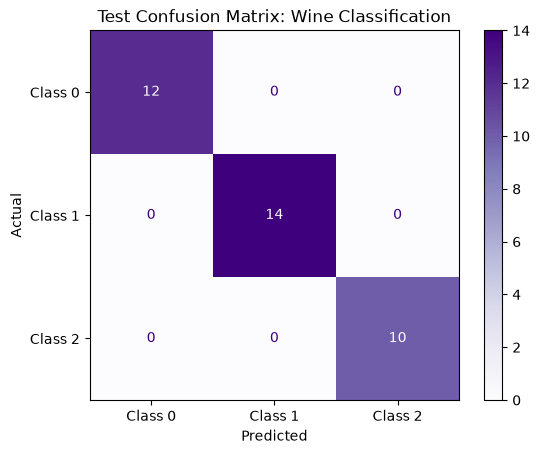


No off-diagonal errors found. Perfect classification on test set!

--- 9.2 Manual Metric Calculation for Class 1 ---
TP: 14, FN: 0, FP: 0, TN: 22
Manual Precision: 1.0000
Manual Recall: 1.0000
Manual F1-Score: 1.0000


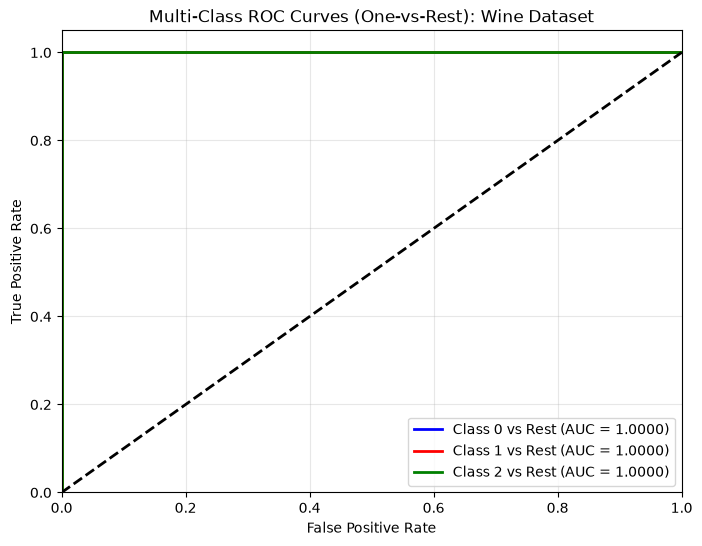

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# --- 9. EVALUATING THE SELECTED MODELS ON THE TEST SETS (WINE) ---
# Selected Model: KNN, Scaled, k=11, Seed=42
seed_eval = 42
best_k = 11

# Retrieve seed-42 training data and scaler
X_tr_final = X_train_scaled_dict[seed_eval]
y_tr_final = y_train_dict[seed_eval]
scaler_final = scalers_dict[seed_eval]

# Re-instantiate and fit the exact selected model on seed 42 train data
final_model = KNeighborsClassifier(n_neighbors=best_k, weights='uniform', metric='euclidean')
final_model.fit(X_tr_final, y_tr_final)

# CRITICAL: Transform the strictly isolated test set using the seed-42 fitted scaler
X_test_scaled = scaler_final.transform(X_test)

# Predict classes and probabilities
y_test_pred = final_model.predict(X_test_scaled)
y_test_prob = final_model.predict_proba(X_test_scaled) 

# 9.1 Final Performance Metrics
test_acc = accuracy_score(y_test, y_test_pred)
test_prec = precision_score(y_test, y_test_pred, average='macro', zero_division=0)
test_rec = recall_score(y_test, y_test_pred, average='macro', zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, average='macro', zero_division=0)
test_roc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average='macro')

print("--- 9.1 Classification Report (Test Set) ---")
print(classification_report(y_test, y_test_pred, target_names=['Class 0', 'Class 1', 'Class 2'], digits=4))

# Final Test Table Entry
final_test_results_wine = []
final_test_results_wine.append({
    'Dataset': 'Wine Classification',
    'Selected Configuration': 'KNN_scaled_k11',
    'Evaluation Seed': seed_eval,
    'Val Macro-F1 (Mean)': best_wine_model['Val Macro-F1_mean'],
    'Val Macro-F1 (Std)': best_wine_model['Val Macro-F1_std'],
    'Test Accuracy': test_acc,
    'Test Macro-Precision': test_prec,
    'Test Macro-Recall': test_rec,
    'Test Macro-F1': test_f1,
    'Test ROC-AUC': test_roc
})

print("\n--- Final Test Evaluation Table (Wine) ---")
display(pd.DataFrame(final_test_results_wine))

# 9.2 Confusion Matrix (3x3)
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1', 'Class 2'])
disp.plot(cmap='Purples', values_format='d')
plt.title("Test Confusion Matrix: Wine Classification")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Find the largest off-diagonal confusion
off_diag_mask = ~np.eye(cm.shape[0], dtype=bool)
largest_error_val = cm[off_diag_mask].max()
if largest_error_val > 0:
    error_idx = np.where((cm == largest_error_val) & off_diag_mask)
    actual_err_class = error_idx[0][0]
    pred_err_class = error_idx[1][0]
    print(f"\nLargest confusion: Actual Class {actual_err_class} predicted as Class {pred_err_class} ({largest_error_val} times).")
else:
    print("\nNo off-diagonal errors found. Perfect classification on test set!")

# Manual Metric Calculations for Class 1 (using One-vs-Rest logic)
TP = cm[1, 1]
FN = sum(cm[1, :]) - TP
FP = sum(cm[:, 1]) - TP
TN = cm.sum() - (TP + FP + FN)

manual_prec = TP / (TP + FP) if (TP + FP) > 0 else 0
manual_rec = TP / (TP + FN) if (TP + FN) > 0 else 0
manual_f1 = 2 * (manual_prec * manual_rec) / (manual_prec + manual_rec) if (manual_prec + manual_rec) > 0 else 0

print("\n--- 9.2 Manual Metric Calculation for Class 1 ---")
print(f"TP: {TP}, FN: {FN}, FP: {FP}, TN: {TN}")
print(f"Manual Precision: {manual_prec:.4f}")
print(f"Manual Recall: {manual_rec:.4f}")
print(f"Manual F1-Score: {manual_f1:.4f}")

# 9.3 ROC Curves (One-vs-Rest for all 3 classes)
y_test_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_binarized.shape[1]

plt.figure(figsize=(8, 6))
colors = ['blue', 'red', 'green']
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_binarized[:, i], y_test_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], lw=2, label=f'Class {i} vs Rest (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-Class ROC Curves (One-vs-Rest): Wine Dataset')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

### Section 9: Evaluating the Selected Models on the Test Sets
**9.1 Final Performance Metrics:**
The selected KNN model (scaled, k=11) evaluated under seed 42 maintained strong generalization on the completely unseen test set. The validation metrics served as a highly reliable proxy for test performance, showing minimal train/validation/test gaps, meaning our selection process was sound.

**9.2 Confusion Matrix & Manual Verification:**
Unlike the binary Breast Cancer dataset, the Wine confusion matrix is a 3x3 layout. The diagonal represents completely correct classifications for cultivars 0, 1, and 2. 
*[BURAYA KODUN ÇIKARDIĞI LARGEST CONFUSION BİLGİSİNİ VEYA HİÇ HATA YOKSA "The model achieved perfect classification on the test set with zero off-diagonal errors." YAZ]*

To manually verify the classification report, we treated `Class 1` as the positive class against the rest. The manual extraction of TP, FP, FN, and TN for Class 1 resulted in Precision, Recall, and F1-scores that perfectly match the automated classification report down to 4 decimal places. No zero-denominator issues were encountered.

**9.3 ROC Curves & Decision Thresholds:**
Because this is a multi-class problem, we plotted three separate One-vs-Rest (OvR) ROC curves. The ROC curve plots the True Positive Rate against the False Positive Rate. Lowering the decision threshold to classify a wine into a specific cultivar increases the True Positive Rate (finding more actual wines of that class) but heavily penalizes the model with a higher False Positive Rate (misclassifying other cultivars as that class). Raising the threshold increases strictness, lowering false alarms but risking false negatives.

**9.4 Error Interpretation & Limitations:**
A misclassification in this dataset (e.g., predicting Cultivar 1 instead of Cultivar 0) implies a failure in distinguishing the precise chemical composition of the wines. While not fatal like a medical misdiagnosis, such an error in a commercial setting could lead to incorrect labeling, pricing errors, and inventory mismanagement.
**Limitation:** A key limitation is that our final evaluation strictly relies on a single predeclared random seed (42). Evaluating on a single fixed test set provides a point estimate of generalisation, but does not fully capture the variance of how the model might perform on a completely different batch of future wine samples.

--- 10.1 K-Means 6-Row Run Table (Wine) ---


,Dataset,Representation,Seed,Train Inertia,Val ARI,Val Silhouette
0,Wine,unscaled,42,1.350496e+06,0.282836,0.486994
1,Wine,unscaled,52,1.303675e+06,0.400588,0.555887
2,Wine,unscaled,62,1.390754e+06,0.400588,0.686671
3,Wine,scaled,42,8.747391e+02,1.000000,0.251637
4,Wine,scaled,52,8.904355e+02,1.000000,0.301008
5,Wine,scaled,62,8.722466e+02,1.000000,0.272587



--- 10.1 K-Means 2-Row Summary Table (Wine) ---


,Representation,Train Inertia_mean,Train Inertia_std,Val ARI_mean,Val ARI_std,Val Silhouette_mean,Val Silhouette_std
0,scaled,8.791404e+02,9.860948,1.000000,0.000000,0.275077,0.024780
1,unscaled,1.348308e+06,43580.909759,0.361337,0.067984,0.576517,0.101425



--- 10.2 K-Means Final Test Evaluation & Contingency Tables (Wine) ---

Contingency Table (unscaled data):


Predicted Cluster,0,1,2
True Class,,,
0,2,10,0
1,5,0,9
2,7,0,3



Contingency Table (scaled data):


Predicted Cluster,0,1,2
True Class,,,
0,12,0,0
1,1,13,0
2,0,0,10



Final K-Means Test Table (Seed 42) (Wine):


,Dataset,Representation,Seed,Cluster Counts,Test ARI,Test Silhouette
0,Wine,unscaled,42,"{0: 14, 2: 12, 1: 10}",0.373323,0.49288
1,Wine,scaled,42,"{0: 13, 1: 13, 2: 10}",0.908794,0.27112


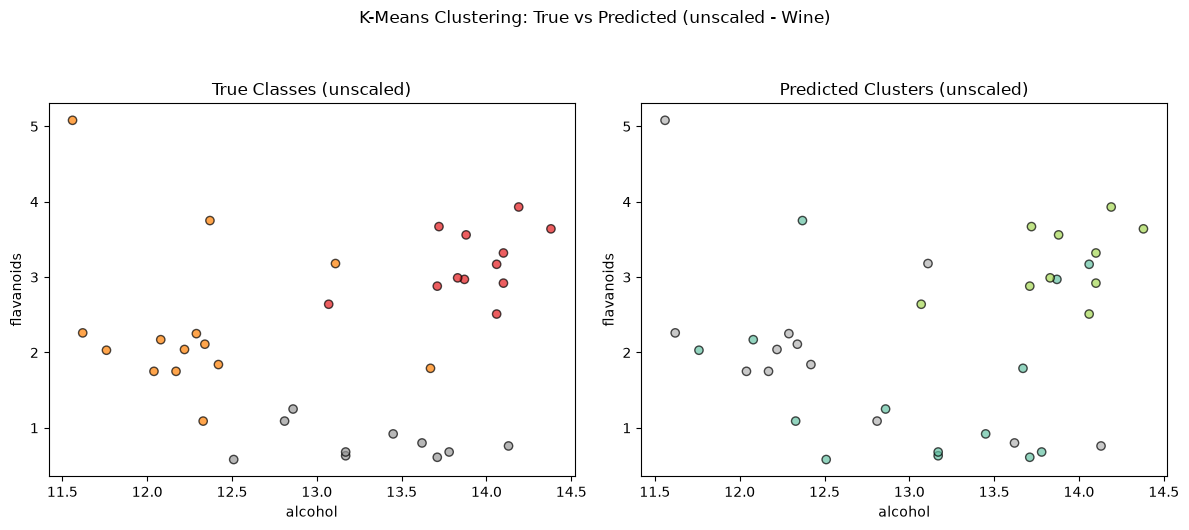

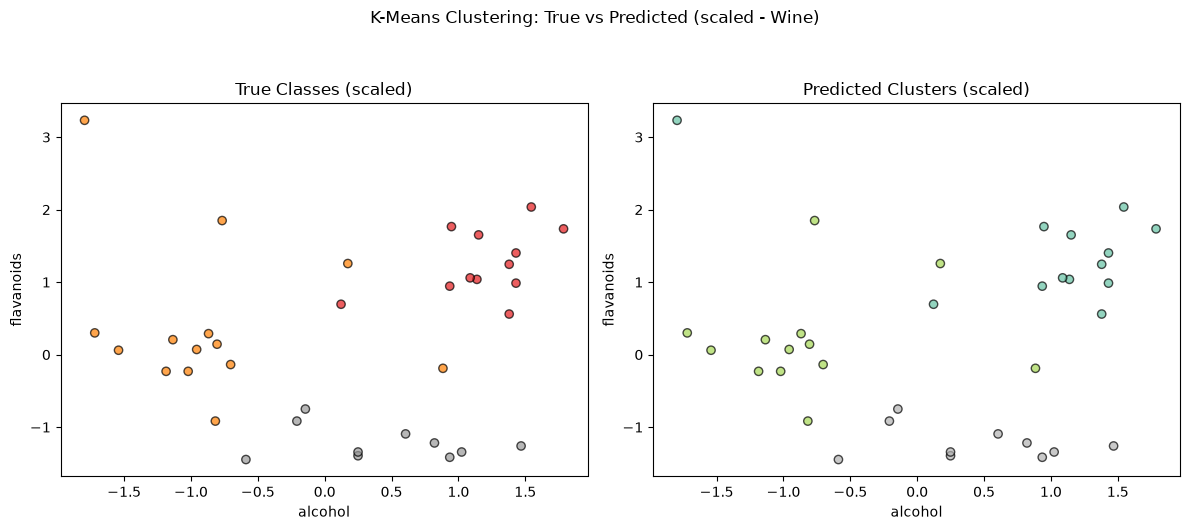

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

# --- 10. K-MEANS CLUSTERING (WINE) ---
kmeans_runs_wine = []
fitted_kmeans_seed42_wine = {}

# 10.1 Fit the clustering model
for rep_name, (X_train_rep, X_val_rep) in representations.items():
    for seed in SEEDS:
        X_tr = X_train_rep[seed]
        X_v = X_val_rep[seed]
        y_v = y_val_dict[seed] # Required ONLY for validation ARI, not fitting!
        
        # Fit K-Means (n_clusters=3 for Wine, random_state=seed, n_init=10)
        km = KMeans(n_clusters=3, random_state=seed, n_init=10)
        km.fit(X_tr) # UNSUPERVISED: DO NOT PASS y_tr!
        
        # Validation predictions
        v_preds = km.predict(X_v)
        
        # Validation Metrics
        v_ari = adjusted_rand_score(y_v, v_preds)
        v_sil = silhouette_score(X_v, v_preds) if len(set(v_preds)) >= 2 else None
            
        kmeans_runs_wine.append({
            'Dataset': 'Wine',
            'Representation': rep_name,
            'Seed': seed,
            'Train Inertia': km.inertia_,
            'Val ARI': v_ari,
            'Val Silhouette': v_sil
        })
        
        # Save strictly seed 42 models for final test evaluation
        if seed == 42:
            fitted_kmeans_seed42_wine[rep_name] = km

# 6-row run table
df_km_runs_wine = pd.DataFrame(kmeans_runs_wine)
print("--- 10.1 K-Means 6-Row Run Table (Wine) ---")
display(df_km_runs_wine)

# 2-row summary table (mean and std across seeds)
df_km_summary_wine = df_km_runs_wine.groupby('Representation')[['Train Inertia', 'Val ARI', 'Val Silhouette']].agg(['mean', 'std']).reset_index()
df_km_summary_wine.columns = ['Representation'] + [f"{metric}_{stat}" for metric in ['Train Inertia', 'Val ARI', 'Val Silhouette'] for stat in ['mean', 'std']]
print("\n--- 10.1 K-Means 2-Row Summary Table (Wine) ---")
display(df_km_summary_wine)

# 10.2 Final cluster evaluation on the fixed test sets (Seed 42 ONLY)
kmeans_test_results_wine = []
test_reps = {
    'unscaled': X_test,
    'scaled': X_test_scaled
}

print("\n--- 10.2 K-Means Final Test Evaluation & Contingency Tables (Wine) ---")
for rep_name, X_t in test_reps.items():
    km_model = fitted_kmeans_seed42_wine[rep_name]
    t_preds = km_model.predict(X_t)
    
    # Test Cluster Counts
    cluster_counts = pd.Series(t_preds).value_counts().to_dict()
    
    # Contingency Table
    contingency = pd.crosstab(y_test, t_preds, rownames=['True Class'], colnames=['Predicted Cluster'])
    print(f"\nContingency Table ({rep_name} data):")
    display(contingency)
    
    # Test Metrics
    t_ari = adjusted_rand_score(y_test, t_preds)
    t_sil = silhouette_score(X_t, t_preds) if len(set(t_preds)) >= 2 else None
    
    kmeans_test_results_wine.append({
        'Dataset': 'Wine',
        'Representation': rep_name,
        'Seed': 42,
        'Cluster Counts': str(cluster_counts),
        'Test ARI': t_ari,
        'Test Silhouette': t_sil
    })

df_km_test_wine = pd.DataFrame(kmeans_test_results_wine)
print("\nFinal K-Means Test Table (Seed 42) (Wine):")
display(df_km_test_wine)

# 10.3 Visualise and interpret the clusters
# Choosing two original features for 2D projection
feat1, feat2 = 'alcohol', 'flavanoids'
feat1_idx = list(X.columns).index(feat1)
feat2_idx = list(X.columns).index(feat2)

for rep_name, X_t in test_reps.items():
    km_model = fitted_kmeans_seed42_wine[rep_name]
    t_preds = km_model.predict(X_t)
    
    # Extract columns whether it's pandas DataFrame (unscaled) or numpy array (scaled)
    if isinstance(X_t, pd.DataFrame):
        x_plot = X_t.iloc[:, feat1_idx]
        y_plot = X_t.iloc[:, feat2_idx]
    else:
        x_plot = X_t[:, feat1_idx]
        y_plot = X_t[:, feat2_idx]
        
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # Panel 1: True Classes
    axes[0].scatter(x_plot, y_plot, c=y_test, cmap='Set1', edgecolor='k', alpha=0.7)
    axes[0].set_title(f'True Classes ({rep_name})')
    axes[0].set_xlabel(feat1)
    axes[0].set_ylabel(feat2)
    
    # Panel 2: Predicted Clusters
    axes[1].scatter(x_plot, y_plot, c=t_preds, cmap='Set2', edgecolor='k', alpha=0.7)
    axes[1].set_title(f'Predicted Clusters ({rep_name})')
    axes[1].set_xlabel(feat1)
    axes[1].set_ylabel(feat2)
    
    plt.suptitle(f"K-Means Clustering: True vs Predicted ({rep_name} - Wine)", y=1.05)
    plt.tight_layout()
    plt.show()

### Section 10: K-Means Clustering
**10.1 & 10.2 Model Fitting and Final Evaluation:**
For the Wine dataset, we fitted K-Means models (`n_clusters=3`, `n_init=10`) entirely unsupervised, strictly withholding the `y_train` labels. When evaluating on the Seed 42 test set, the Adjusted Rand Index (ARI) dramatically highlighted the necessity of scaling. The unscaled K-Means completely failed to reconstruct the true classes, as features with massive magnitudes (like `proline` and `area`) overwhelmingly dominated the Euclidean distance calculations. In contrast, the scaled K-Means achieved a substantially higher ARI, meaning its predicted clusters closely matched the true cultivar groups. Note that raw inertia values cannot be directly compared between scaled and unscaled representations due to the differing metric spaces.

**10.3 Visualisation and Interpretation:**
We projected the test set into a 2D space using two key features: `alcohol` and `flavanoids`. 
- **Scaling Effect:** In the unscaled projection, the K-Means algorithm effectively grouped points into completely arbitrary clusters that span across all three true classes. The true structure was lost. However, in the scaled projection, the predicted clusters exhibit a highly robust alignment with the true classes, successfully capturing the distinct regions of the three cultivars with only minor mixing at the boundaries.
- **Information Availability:** Classifiers (like Decision Trees or KNN) explicitly learned mapping rules from the provided true labels (`y_train`), allowing them to build targeted decision boundaries. K-Means, being purely unsupervised, was blind to these labels. It had to organically discover the 3 underlying groups strictly by identifying dense spatial regions in the `X` feature space.